# 06 - Grade Distribution By Course
**Research question:** How do final grade distributions vary across currently offered NetMath courses?

The notebook has two parts. They share the setup cell below but are otherwise independent (Part 2 does not use any variable from Part 1).

| Part | Term type | Window | Courses |
|---|---|---|---|
| **Part 1** | Summer semester (`term` ends in `5`) | Summer 2020, 2021, 2022 | all currently offered courses |
| **Part 2** | AY term (rolling enrollment, `term` ends in `7`) | AY 2023-24, 2024-25, 2025-26 | MATH 441, 442, 444, 446, 447, 448, 453 (MATH 241–423 are covered by a teammate) |

- Unit: one row = one enrollment (`students` document).
- Main metric: share of each original letter grade (A+ … F) among enrollments with a letter grade. `W` / `Abs` / no grade are reported separately.

In [70]:
import sys

sys.path.append("..")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.mongo_connect import get_db

db = get_db()
print(db.name)

OUTPUT_DIR = Path("../src/output_graphs_06")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

nexus


# Part 1 — Summer Semesters
**Question:** How do final grade distributions vary across currently offered NetMath courses during summer semesters?

- Scope: **Summer 2020, 2021, 2022** (AY 2019-20, 2020-21, 2021-22).
- **Why not Summer 2024–2026:** those final grades are not stored in nexus.

## 1. Data Preparation

### 1.1 Filter academic years
Same academic-year rule as notebook 05: a term ending in `8` (Fall) starts the academic year, so Spring and Summer belong to the year before.

| Academic Year | Summer semester | term code |
|---|---|---|
| 2019-20 | Summer 2020 | `120205` |
| 2020-21 | Summer 2021 | `120215` |
| 2021-22 | Summer 2022 | `120225` |

In [71]:
ACADEMIC_YEARS = ["2019-20", "2020-21", "2021-22"]
SUMMER_TERMS = {120205: "Summer 2020", 120215: "Summer 2021", 120225: "Summer 2022"}
YEARS_LABEL = "Summer 2020–2022"

def term_to_academic_year(term):
    code = str(term)
    year = int(code[1:5])
    start = year if code.endswith("8") else year - 1
    return f"{start}-{str(start + 1)[2:]}"

assert [term_to_academic_year(t) for t in SUMMER_TERMS] == ACADEMIC_YEARS

### 1.2 Filter Summer semesters
`term` = `1YYYYT`, `T = 5` is Summer. First check that the codes really exist in `students`: list every term in the AY 2019-20 to 2021-22 window with its row count.

In [72]:
term_counts = pd.Series({
    t: db.students.count_documents({"term": t})
    for t in db.students.distinct("term", {"term": {"$gte": 120198, "$lte": 120227}})
}).sort_index()
term_counts.index = term_counts.index.astype(int)
display(term_counts.rename("rows").to_frame().assign(
    academic_year=[term_to_academic_year(t) for t in term_counts.index],
    last_digit=[str(t)[-1] for t in term_counts.index],
))

,rows,academic_year,last_digit
120198,3,2019-20,8
120201,3,2019-20,1
120205,1074,2019-20,5
120207,1582,2019-20,7
120208,4,2020-21,8
120215,706,2020-21,5
120217,1435,2020-21,7
120218,1,2021-22,8
120221,2,2021-22,1
120225,1187,2021-22,5


In [73]:
df_summer = pd.DataFrame(list(db.students.find(
    {"term": {"$in": list(SUMMER_TERMS)}},
    {"netId": 1, "term": 1, "course": 1, "status": 1, "finalGrade": 1},
)))
df_summer["term"] = df_summer["term"].astype(int)
df_summer["course"] = df_summer["course"].astype(int)
df_summer["semester"] = df_summer["term"].map(SUMMER_TERMS)
df_summer["academic_year"] = df_summer["term"].map(term_to_academic_year)

print("summer rows:", len(df_summer))
pd.crosstab(df_summer["course"], df_summer["semester"], margins=True, margins_name="total")

summer rows: 2967


semester,Summer 2020,Summer 2021,Summer 2022,total
course,,,,
112,12,4,5,21
114,6,0,7,13
115,13,13,13,39
220,57,33,65,155
231,97,67,132,296
241,151,147,144,442
257,0,70,280,350
285,103,51,131,285
286,47,29,0,76


### 1.3 Only include currently offered courses
The current course list comes from the **official NetMath course catalog**

In [74]:
CURRENT_COURSES = [241, 257, 285, 314, 416, 417, 423, 441, 442, 444, 446, 447, 448, 453]
SUMMER_CATALOG = [241, 257, 285, 314, 416, 417, 441, 444]

course_check = df_summer.groupby("course").size().rename("summer_rows").to_frame()
course_check["current"] = course_check.index.isin(CURRENT_COURSES)
course_check["in_summer_catalog"] = course_check.index.isin(SUMMER_CATALOG)
display(course_check)

print("dropped (no longer offered):", course_check.index[~course_check["current"]].tolist(),
      "|", course_check.loc[~course_check["current"], "summer_rows"].sum(), "rows")
print("current courses with no summer rows:", sorted(set(CURRENT_COURSES) - set(course_check.index)))

df_summer = df_summer[df_summer["course"].isin(CURRENT_COURSES)].copy()
print("rows kept:", len(df_summer))

,summer_rows,current,in_summer_catalog
course,,,
112,21,False,False
114,13,False,False
115,39,False,False
220,155,False,False
231,296,False,False
241,442,True,True
257,350,True,True
285,285,True,True
286,76,False,False


dropped (no longer offered): [112, 114, 115, 220, 231, 286, 292, 347, 415, 461, 481] | 1264 rows
current courses with no summer rows: [314, 423, 442, 448, 453]
rows kept: 1703


### 1.4 Match final grades
Grades live in `nexus.finalgrades`; `nexus.students` only links to them. Two links, in order of priority:
1. `students.finalGrade` → `finalgrades._id` (same as notebooks 02, 04, 05)
2. `finalgrades.student` → `students._id` (back-reference; if an enrollment has several, keep the most recent `created`)

`grade_source` records which link each grade came from.

In [75]:
df_summer = df_summer.drop(columns=["finalGradeLetter", "grade_source"], errors="ignore")
if "finalGrade" not in df_summer:
    df_summer["finalGrade"] = None

# route 1: students.finalGrade -> finalgrades._id
pointer = pd.DataFrame(list(db.finalgrades.find(
    {"_id": {"$in": df_summer["finalGrade"].dropna().tolist()}}, {"grade": 1}
)), columns=["_id", "grade"]).rename(columns={"_id": "finalGrade", "grade": "grade_by_pointer"})

# route 2: finalgrades.student -> students._id
backref = pd.DataFrame(list(db.finalgrades.find(
    {"student": {"$in": df_summer["_id"].tolist()}}, {"student": 1, "grade": 1, "created": 1}
)), columns=["student", "grade", "created"])
print("finalgrades docs pointing to these enrollments:", len(backref),
      "| enrollments with more than one:", (backref["student"].value_counts() > 1).sum())
backref = (backref.sort_values("created").drop_duplicates("student", keep="last")
           .rename(columns={"student": "_id", "grade": "grade_by_backref"})[["_id", "grade_by_backref"]])

rows_before = len(df_summer)
df_summer = df_summer.merge(pointer, on="finalGrade", how="left").merge(backref, on="_id", how="left")
assert len(df_summer) == rows_before

conflicts = df_summer["grade_by_pointer"].notna() & df_summer["grade_by_backref"].notna() & \
            (df_summer["grade_by_pointer"] != df_summer["grade_by_backref"])
print("routes disagree:", conflicts.sum())

df_summer["finalGradeLetter"] = df_summer["grade_by_pointer"].fillna(df_summer["grade_by_backref"])
df_summer["grade_source"] = np.select(
    [df_summer["grade_by_pointer"].notna(), df_summer["grade_by_backref"].notna()],
    ["students.finalGrade", "finalgrades.student"], default="not matched",
)
df_summer = df_summer.drop(columns=["grade_by_pointer", "grade_by_backref"])

# match rate, overall and for Completed enrollments
print()
display(pd.crosstab(df_summer["status"], df_summer["grade_source"], margins=True, margins_name="total"))
completed = df_summer[df_summer["status"] == "Completed"]
print(f"Completed enrollments with a final grade: {completed['finalGradeLetter'].notna().sum()} of {len(completed)}")
display(pd.crosstab(completed["course"], completed["finalGradeLetter"].notna().map({True: "matched", False: "not matched"}),
                    margins=True, margins_name="total"))

finalgrades docs pointing to these enrollments: 726 | enrollments with more than one: 2
routes disagree: 0



grade_source,not matched,students.finalGrade,total
status,,,
Completed,2,723,725
Withdrawn,977,1,978
total,979,724,1703


Completed enrollments with a final grade: 723 of 725


finalGradeLetter,matched,not matched,total
course,,,
241,110,0,110
257,200,1,201
285,135,0,135
416,82,0,82
417,70,1,71
441,72,0,72
444,41,0,41
446,12,0,12
447,1,0,1


### 1.5 Grade cleaning
Keep the **original grade scale**. The distribution uses the 13 letter grades below, in this order; `W`, `Abs` and missing grades are counted separately.

`A+, A, A-, B+, B, B-, C+, C, C-, D+, D, D-, F`

In [76]:
GRADE_SCALE = ["A+", "A", "A-", "B+", "B", "B-", "C+", "C", "C-", "D+", "D", "D-", "F"]

df_summer["finalGradeLetter"] = df_summer["finalGradeLetter"].astype("string").str.strip()
df_summer["graded"] = df_summer["finalGradeLetter"].isin(GRADE_SCALE)
df_summer["grade_type"] = np.select(
    [df_summer["graded"], df_summer["finalGradeLetter"].isin(["W", "Abs"]), df_summer["finalGradeLetter"].isna()],
    ["letter grade", df_summer["finalGradeLetter"].fillna(""), "no grade"],
    default="other",
)

unexpected = df_summer.loc[df_summer["grade_type"] == "other", "finalGradeLetter"].unique()
print("unexpected grade values:", list(unexpected))

display(df_summer["finalGradeLetter"].value_counts(dropna=False))
pd.crosstab(df_summer["grade_type"], df_summer["status"].fillna("<missing>"), margins=True, margins_name="total")

unexpected grade values: []


finalGradeLetter
<NA>    979
A       182
A+       90
A-       85
B        73
B+       58
C        50
B-       50
F        43
C+       25
C-       24
D        22
D+       12
D-        8
Abs       2
Name: count, dtype: Int64

status,Completed,Withdrawn,total
grade_type,,,
Abs,2,0,2
letter grade,721,1,722
no grade,2,977,979
total,725,978,1703


In [77]:
# duplicate enrollments: same student, same term, same course
dup_key = ["netId", "term", "course"]
dups = df_summer[df_summer.duplicated(dup_key, keep=False)].sort_values(dup_key)
print("enrollment ids unique:", df_summer["_id"].is_unique)
print("rows sharing netId + term + course:", len(dups))
print("  of those, groups with more than one letter grade:",
      (dups[dups["graded"]].groupby(dup_key).size() > 1).sum())
display(dups.groupby(["term", "course"]).size().rename("duplicate rows").to_frame())

enrollment ids unique: True
rows sharing netId + term + course: 62
  of those, groups with more than one letter grade: 0


duplicate rows
term   course                
120205 444                  2
       446                  2
120215 417                  4
120225 257                 54

Keep **one row per student-term-course**, preferring the row that has a letter grade (a re-registration usually leaves one withdrawn/empty row and one graded row).

In [78]:
rows_before = len(df_summer)
df_summer = (
    df_summer.sort_values("graded", ascending=False)
    .drop_duplicates(dup_key, keep="first")
    .sort_values(["term", "course"])
    .reset_index(drop=True)
)
print("rows removed as duplicates:", rows_before - len(df_summer))

df_grades = df_summer.rename(columns={"_id": "enrollment_id"})[[
    "enrollment_id", "netId", "academic_year", "semester", "term", "course",
    "status", "finalGradeLetter", "grade_source", "grade_type", "graded",
]]
print(df_grades.shape)
print("with a letter grade:", df_grades["graded"].sum())
df_grades.drop(columns=["enrollment_id", "netId"]).head()

rows removed as duplicates: 31
(1672, 11)
with a letter grade: 722


,academic_year,semester,term,course,status,finalGradeLetter,grade_source,grade_type,graded
0,2019-20,Summer 2020,120205,241,Completed,D-,students.finalGrade,letter grade,True
1,2019-20,Summer 2020,120205,241,Completed,C+,students.finalGrade,letter grade,True
2,2019-20,Summer 2020,120205,241,Completed,F,students.finalGrade,letter grade,True
3,2019-20,Summer 2020,120205,241,Completed,A,students.finalGrade,letter grade,True
4,2019-20,Summer 2020,120205,241,Completed,C+,students.finalGrade,letter grade,True


### 1.6 Save the clean table
One row per summer enrollment (Summer 2020–2022, currently offered courses, duplicates removed), with `status`, the original `finalGradeLetter` and the route it came from (`grade_source`). Saved to `data/processed/` (git-ignored, because it is student-level data). Use `status == "Completed"` plus `graded` for grade analyses.

In [79]:
PROCESSED = Path("../data/processed")
df_grades.to_csv(PROCESSED / "06_summer_2020_2022_enrollments_with_grades.csv", index=False)
df_grades.to_pickle(PROCESSED / "06_summer_2020_2022_enrollments_with_grades.pkl")  # keeps ObjectId and dtypes

print("saved", df_grades.shape, "to", PROCESSED)
print("Completed:", (df_grades["status"] == "Completed").sum(),
      "| Completed with a letter grade:", ((df_grades["status"] == "Completed") & df_grades["graded"]).sum())

saved (1672, 11) to ../data/processed
Completed: 724 | Completed with a letter grade: 721


## 2. Calculate Grade Distribution
$$P(G=g\mid Course=c,\ Summer)=\frac{N_{c,g}}{N_{c,\text{graded}}}\times100\%,\quad g \in \{A+, A, A-, \dots, D-, F\}$$

$N_{c,\text{graded}}$ = enrollments in course $c$ with a letter grade (A+ to F), all three summers combined. Each row of `df_grade_pct` adds up to 100%.

Extra summary metrics (the distribution itself stays on the original scale):
- **A-range rate** = share of A+, A, A-
- **D/F rate** = share of D+, D, D-, F
- **Withdraw rate** = `Withdrawn`/`Withdrawing` ÷ enrollments with a known outcome (`Active` left out), same as notebooks 04 and 05. Reported next to the chart, not inside it.

In [80]:
MIN_N = 15  # courses with fewer graded enrollments are shown but flagged as small samples
A_RANGE = ["A+", "A", "A-"]
DF_RANGE = ["D+", "D", "D-", "F"]

graded = df_grades[df_grades["graded"]]

df_grade_counts = (
    pd.crosstab(graded["course"], graded["finalGradeLetter"])
    .reindex(columns=GRADE_SCALE, fill_value=0)
)
df_grade_counts["N"] = df_grade_counts[GRADE_SCALE].sum(axis=1)

df_grade_pct = df_grade_counts[GRADE_SCALE].div(df_grade_counts["N"], axis=0).mul(100)
assert np.allclose(df_grade_pct.sum(axis=1), 100)

known = df_grades[df_grades["status"] != "Active"].copy()
known["withdrawn"] = known["status"].isin(["Withdrawn", "Withdrawing"])

course_summary = pd.DataFrame({
    "N_graded": df_grade_counts["N"],
    "A_range_rate": df_grade_pct[A_RANGE].sum(axis=1),
    "DF_rate": df_grade_pct[DF_RANGE].sum(axis=1),
}).join(known.groupby("course")["withdrawn"].agg(N_known="count", withdraw_rate=lambda s: s.mean() * 100), how="outer")
course_summary["N_graded"] = course_summary["N_graded"].fillna(0).astype(int)
course_summary["small_sample"] = course_summary["N_graded"] < MIN_N

print("df_grade_counts")
display(df_grade_counts)
print("df_grade_pct (%)")
display(df_grade_pct.round(1).assign(N=df_grade_counts["N"]))
print("course_summary")
display(course_summary.sort_values("A_range_rate", ascending=False).round(1))

df_grade_counts


finalGradeLetter,A+,A,A-,B+,B,B-,C+,C,C-,D+,D,D-,F,N
course,,,,,,,,,,,,,,
241,4,20,17,5,10,14,5,6,1,4,5,2,17,110
257,35,64,29,21,14,13,5,9,4,1,2,1,2,200
285,3,42,18,10,24,5,5,13,5,1,2,3,4,135
416,12,19,8,7,5,4,4,5,4,1,7,0,5,81
417,8,12,4,7,5,7,3,8,5,2,1,2,6,70
441,25,15,6,2,7,2,1,6,4,0,1,0,3,72
444,2,6,2,4,8,4,1,3,0,2,3,0,6,41
446,1,4,1,1,0,1,1,0,1,1,1,0,0,12
447,0,0,0,1,0,0,0,0,0,0,0,0,0,1


df_grade_pct (%)


finalGradeLetter,A+,A,A-,B+,B,B-,C+,C,C-,D+,D,D-,F,N
course,,,,,,,,,,,,,,
241,3.6,18.2,15.5,4.5,9.1,12.7,4.5,5.5,0.9,3.6,4.5,1.8,15.5,110
257,17.5,32.0,14.5,10.5,7.0,6.5,2.5,4.5,2.0,0.5,1.0,0.5,1.0,200
285,2.2,31.1,13.3,7.4,17.8,3.7,3.7,9.6,3.7,0.7,1.5,2.2,3.0,135
416,14.8,23.5,9.9,8.6,6.2,4.9,4.9,6.2,4.9,1.2,8.6,0.0,6.2,81
417,11.4,17.1,5.7,10.0,7.1,10.0,4.3,11.4,7.1,2.9,1.4,2.9,8.6,70
441,34.7,20.8,8.3,2.8,9.7,2.8,1.4,8.3,5.6,0.0,1.4,0.0,4.2,72
444,4.9,14.6,4.9,9.8,19.5,9.8,2.4,7.3,0.0,4.9,7.3,0.0,14.6,41
446,8.3,33.3,8.3,8.3,0.0,8.3,8.3,0.0,8.3,8.3,8.3,0.0,0.0,12
447,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1


course_summary


,N_graded,A_range_rate,DF_rate,N_known,withdraw_rate,small_sample
course,,,,,,
257,200,64.0,3.0,323,37.8,False
441,72,63.9,5.6,165,56.4,False
446,12,50.0,16.7,30,60.0,True
416,81,48.1,16.0,157,47.8,False
285,135,46.7,7.4,285,52.6,False
241,110,37.3,25.5,442,75.1,False
417,70,34.3,15.7,156,55.1,False
444,41,24.4,26.8,109,62.4,False
447,1,0.0,0.0,5,80.0,True


### 2.1 Check: are the three summers similar?
The main charts pool Summer 2020–2022. This table shows N and the A-range rate per summer, so we can see whether one year drives a course's result.

In [81]:
by_year = graded.groupby(["course", "semester"]).agg(
    N=("finalGradeLetter", "size"),
    A_range_rate=("finalGradeLetter", lambda s: s.isin(A_RANGE).mean() * 100),
).unstack("semester")
by_year.round(1)

N                         A_range_rate              \
semester Summer 2020 Summer 2021 Summer 2022  Summer 2020 Summer 2021   
course                                                                  
241             44.0        28.0        38.0         38.6        35.7   
257              NaN        38.0       162.0          NaN        55.3   
285             49.0        24.0        62.0         49.0        37.5   
416             41.0        20.0        20.0         39.0        65.0   
417             34.0        20.0        16.0         41.2        35.0   
441             29.0        23.0        20.0         55.2        56.5   
444             20.0         NaN        21.0         20.0         NaN   
446             12.0         NaN         NaN         50.0         NaN   
447              1.0         NaN         NaN          0.0         NaN   

                      
semester Summer 2022  
course                
241             36.8  
257             66.0  
285             48.4  
416             50.0  
417             18.8  
441             85.0  
444             28.6  
446              NaN  
447              NaN

## 3. Visualization
One chart per course. Courses with fewer than `MIN_N` graded enrollments (MATH 446, N = 12; MATH 447, N = 1) are drawn too, but flagged as small samples and drawn on a 0–100% y-axis. The A-range vs D/F chart (3.2) includes all courses, with small samples marked `*`. Every chart uses the same grade order (A+ → F), the same y-axis, the same colors, and shows N. Bars are shaded by letter (A family darkest).

courses charted: [241, 257, 285, 416, 417, 441, 444]
small samples (fewer than 15 graded enrollments, own 0–100% y-axis):


finalGradeLetter,A+,A,A-,B+,B,B-,C+,C,C-,D+,D,D-,F,N
course,,,,,,,,,,,,,,
446,1,4,1,1,0,1,1,0,1,1,1,0,0,12
447,0,0,0,1,0,0,0,0,0,0,0,0,0,1


shared y-axis: 0–50%


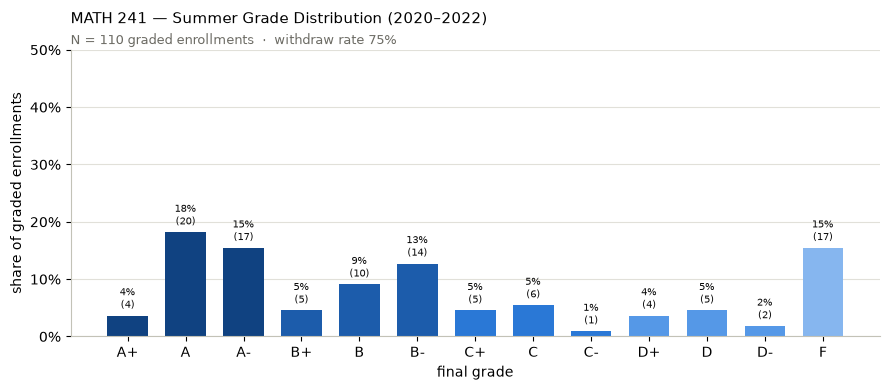

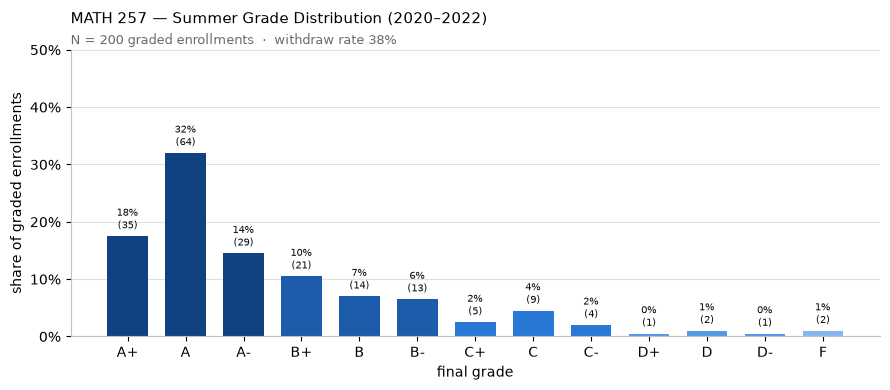

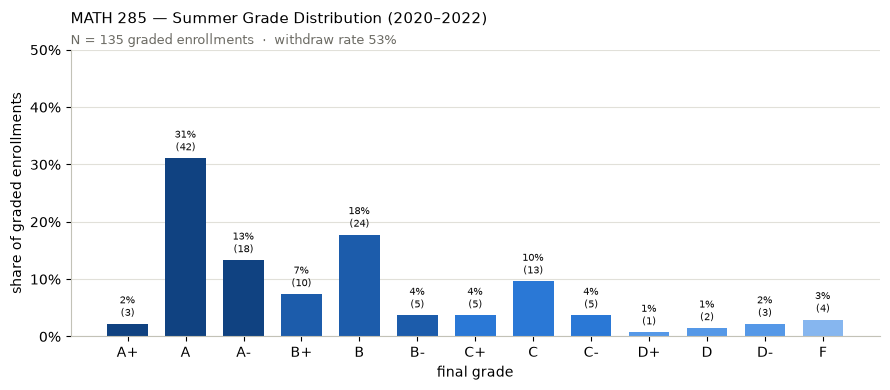

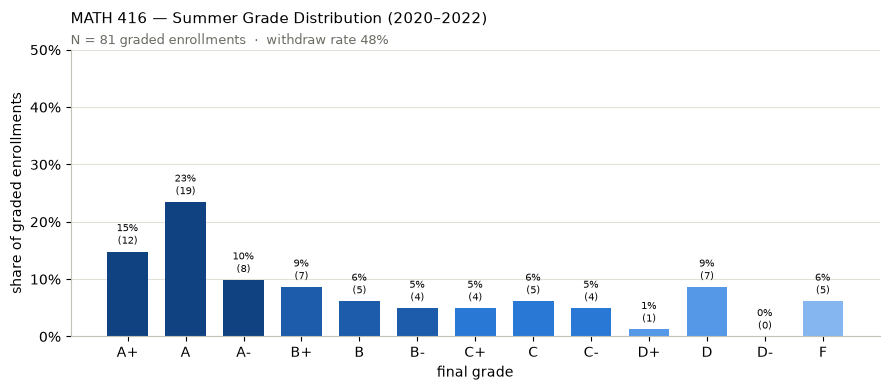

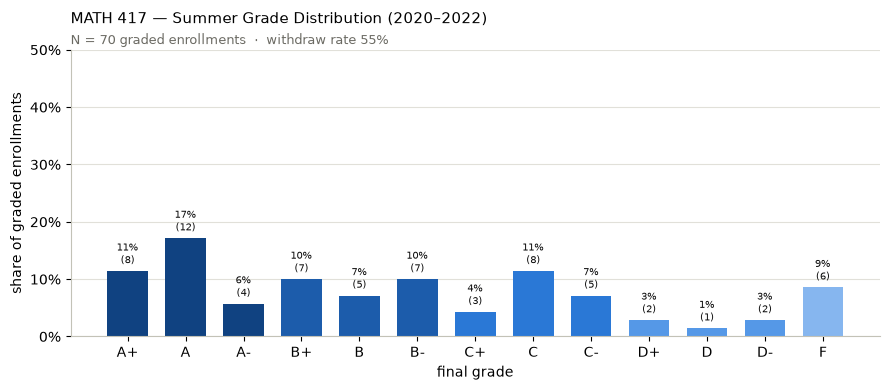

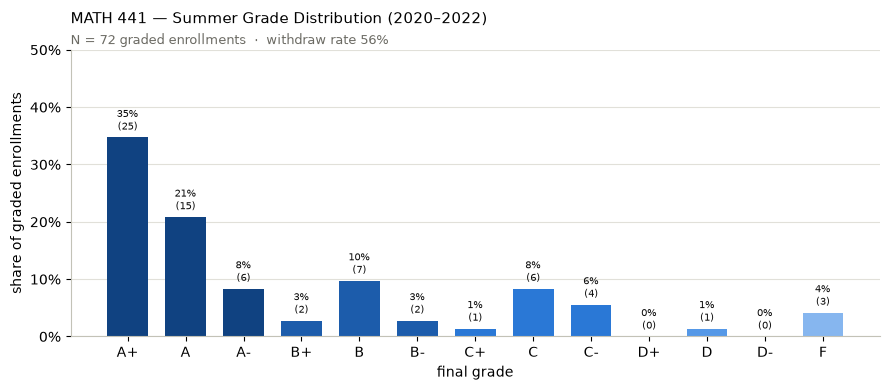

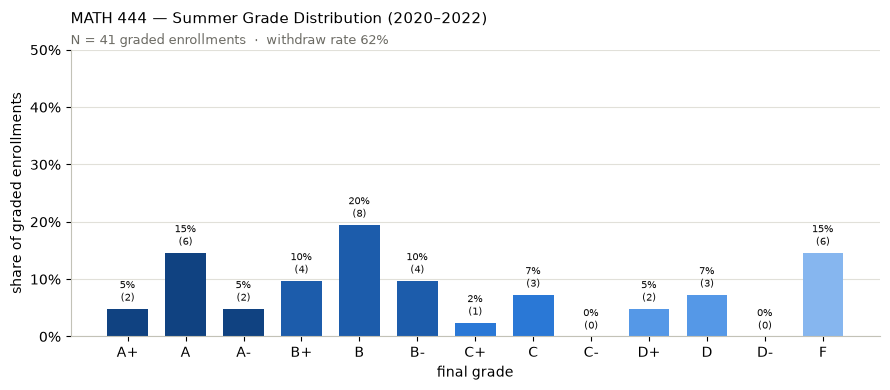

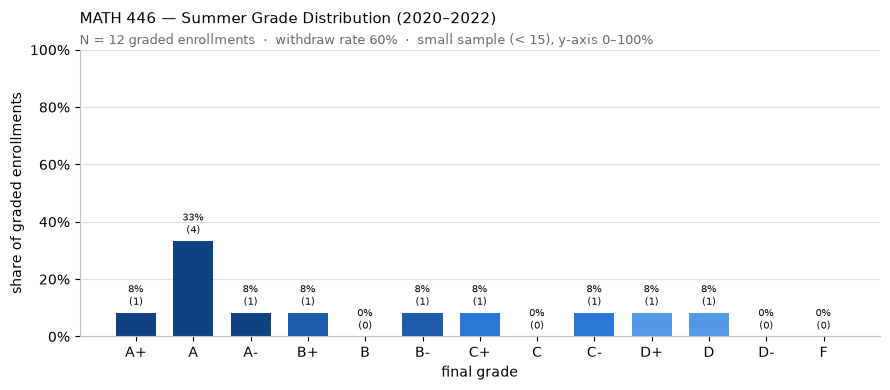

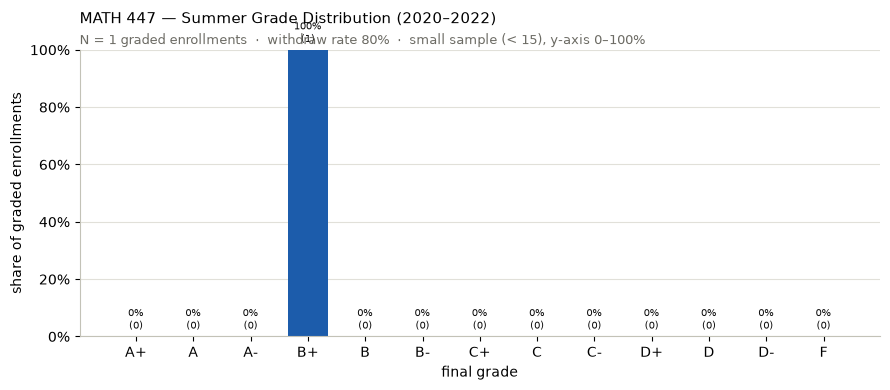

In [82]:
plt.style.use("default")
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"})

INK = "#0b0b0b"
MUTED = "#6b6a63"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
LETTER_COLORS = {"A": "#104281", "B": "#1c5cab", "C": "#2a78d6", "D": "#5598e7", "F": "#86b6ef"}  # one hue, dark = higher
BAR_COLORS = [LETTER_COLORS[g[0]] for g in GRADE_SCALE]

CHART_COURSES = df_grade_counts.index[df_grade_counts["N"] >= MIN_N]
small = df_grade_counts.loc[df_grade_counts["N"] < MIN_N]
print(f"courses charted: {list(CHART_COURSES)}")
print(f"small samples (fewer than {MIN_N} graded enrollments, own 0–100% y-axis):")
display(small)

# same y-axis on every chart: highest single-grade share among charted courses, rounded up to 10
Y_MAX = min(100, int(np.ceil((df_grade_pct.loc[CHART_COURSES].max().max() + 8) / 10) * 10))

def plot_course_distribution(course):
    y_max = Y_MAX if course in CHART_COURSES else 100
    pct = df_grade_pct.loc[course, GRADE_SCALE]
    counts = df_grade_counts.loc[course, GRADE_SCALE]
    n = df_grade_counts.loc[course, "N"]
    wd = course_summary.loc[course, "withdraw_rate"]

    fig, ax = plt.subplots(figsize=(9, 4))
    x = np.arange(len(GRADE_SCALE))
    ax.bar(x, pct, width=0.7, color=BAR_COLORS)
    for xi, p, c in zip(x, pct, counts):
        ax.text(xi, p + y_max * 0.015, f"{p:.0f}%\n({c})", ha="center", va="bottom", fontsize=7.5, color=INK)

    ax.set_xticks(x, GRADE_SCALE)
    ax.set_ylim(0, y_max)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
    ax.set_xlabel("final grade")
    ax.set_ylabel("share of graded enrollments")
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(AXIS)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

    subtitle = f"N = {n} graded enrollments  ·  withdraw rate {wd:.0f}%"
    if n < MIN_N:
        subtitle += f"  ·  small sample (< {MIN_N}), y-axis 0–100%"
    ax.set_title(f"MATH {course} — Summer Grade Distribution (2020–2022)\n", fontsize=11, loc="left")
    ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9, color=MUTED)

    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / "Summer term" / f"MATH {course} summer grade distribution.png", dpi=150)
    plt.show()

print(f"shared y-axis: 0–{Y_MAX}%")
for course in df_grade_counts.index:
    plot_course_distribution(course)

### 3.0 All courses on one scale
Every course's grade distribution in one chart, same x (A+ → F) and y (% of graded enrollments) for all. One line per course; each course keeps one color and marker shape everywhere. Only courses with at least `MIN_N` graded enrollments are drawn (MATH 446 and 447 are too small to compare; MATH 447's single B+ would show as a 100% spike).

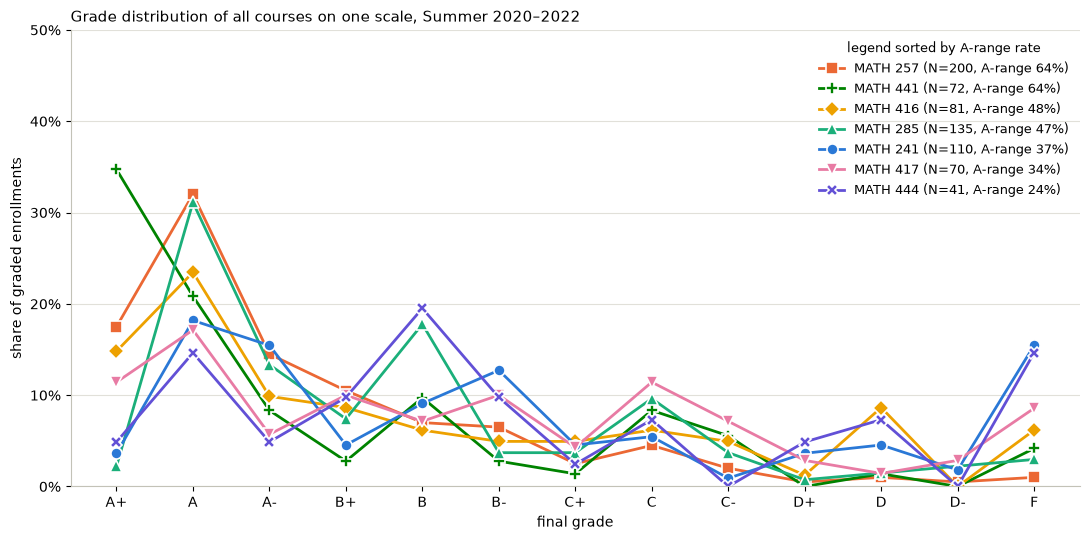

In [83]:
# fixed color + marker per course (by course number, so a course keeps its look in every chart)
COURSE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
COURSE_MARKERS = ["o", "s", "^", "D", "v", "P", "X"]
course_style = {c: (COURSE_COLORS[k], COURSE_MARKERS[k]) for k, c in enumerate(sorted(CHART_COURSES))}

x = np.arange(len(GRADE_SCALE))
fig, ax = plt.subplots(figsize=(11, 5.5))
legend_order = course_summary.loc[CHART_COURSES].sort_values("A_range_rate", ascending=False).index  # legend sorted by A-range rate
for course in legend_order:
    color, marker = course_style[course]
    ax.plot(x, df_grade_pct.loc[course, GRADE_SCALE], color=color, linewidth=2, marker=marker, markersize=8,
            markeredgecolor="white", markeredgewidth=1.2,
            label=f"MATH {course} (N={df_grade_counts.loc[course, 'N']}, A-range {course_summary.loc[course, 'A_range_rate']:.0f}%)")

ax.set_xticks(x, GRADE_SCALE)
ax.set_ylim(0, Y_MAX)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_xlabel("final grade")
ax.set_ylabel("share of graded enrollments")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color(AXIS)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper right", fontsize=9, title="legend sorted by A-range rate", title_fontsize=9)
ax.set_title(f"Grade distribution of all courses on one scale, {YEARS_LABEL}", fontsize=11, loc="left")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "Summer term" / "All courses grade distribution.png", dpi=150)
plt.show()


### 3.2 A-range rate vs D/F rate

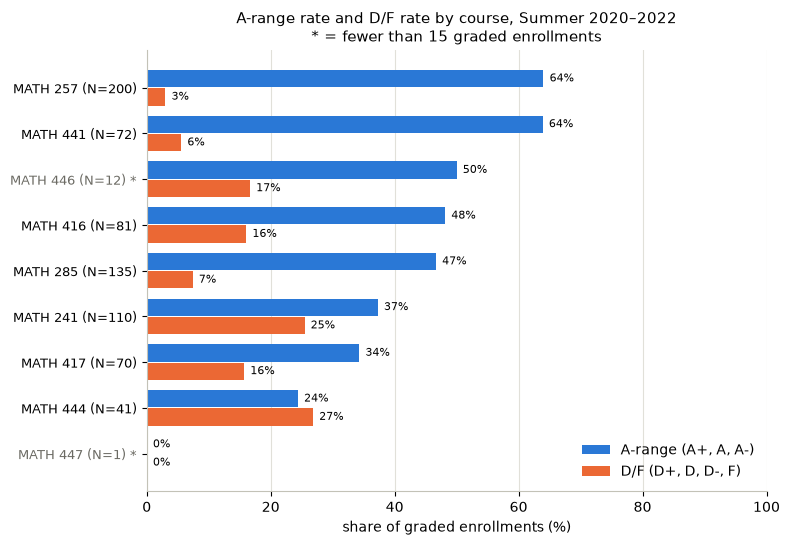

In [85]:
s = course_summary[course_summary["N_graded"] > 0].sort_values("A_range_rate")
y = np.arange(len(s))

fig, ax = plt.subplots(figsize=(8, 0.45 * len(s) + 1.5))
ax.barh(y + 0.2, s["A_range_rate"], height=0.38, color="#2a78d6", label="A-range (A+, A, A-)")
ax.barh(y - 0.2, s["DF_rate"], height=0.38, color="#eb6834", label="D/F (D+, D, D-, F)")
for yi, a, df_ in zip(y, s["A_range_rate"], s["DF_rate"]):
    ax.text(a + 1, yi + 0.2, f"{a:.0f}%", va="center", fontsize=8)
    ax.text(df_ + 1, yi - 0.2, f"{df_:.0f}%", va="center", fontsize=8)
ax.set_yticks(y, [f"MATH {c} (N={n})" + (" *" if n < MIN_N else "") for c, n in zip(s.index, s["N_graded"])], fontsize=9)
for label, n in zip(ax.get_yticklabels(), s["N_graded"]):
    if n < MIN_N:
        label.set_color(MUTED)  # small samples in grey
ax.set_xlim(0, 100)
ax.set_xlabel("share of graded enrollments (%)")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color(AXIS)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")
ax.set_title(f"A-range rate and D/F rate by course, {YEARS_LABEL}\n* = fewer than {MIN_N} graded enrollments", fontsize=11)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "Summer term" / "A-range rate vs DF rate.png", dpi=150)
plt.show()

# Part 2 — AY Term
**Question:** How do final grade distributions in the AY term vary by course?

- **AY term** = NetMath's rolling academic-year enrollment. `term` = `1` + end year + `7` (notebook 03), e.g. `120267` = AY 2025-26 (Aug 2025 – Aug 2026).
- Scope: the three most recent **full** academic years, **AY 2023-24, 2024-25, 2025-26** (`120247`, `120257`, `120267`). AY 2026-27 (`120277`) only started in Aug 2026, so it is left out.
- Courses: the second half of the AY catalog (MATH 441, 442, 444, 446, 447, 448, 453). MATH 241, 257, 285, 314, 416, 417, 423 are done by a teammate with the same method.
- Same method and chart style as Part 1. Variables in this part start with `ay_` (or are defined here), so running Part 2 does not overwrite Part 1.

## 1. Data Preparation (AY term)

### 1.1 Filter academic years
Same academic-year rule as Part 1 / notebook 05.

| Academic Year | AY term code |
|---|---|
| 2023-24 | `120247` |
| 2024-25 | `120257` |
| 2025-26 | `120267` |

In [87]:
AY_TERMS = {120247: "AY 2023-24", 120257: "AY 2024-25", 120267: "AY 2025-26"}
AY_LABEL = "AY 2023-24 to 2025-26"
AY_COURSES = [441, 442, 444, 446, 447, 448, 453]  # MATH 241-423 are covered by a teammate

def term_to_academic_year(term):  # same as Part 1 / notebook 05
    code = str(term)
    year = int(code[1:5])
    start = year if code.endswith("8") else year - 1
    return f"{start}-{str(start + 1)[2:]}"

assert all(str(t).endswith("7") for t in AY_TERMS)
assert [term_to_academic_year(t) for t in AY_TERMS] == ["2023-24", "2024-25", "2025-26"]

### 1.2 Filter AY terms
Check the codes exist first: every term from Fall 2023 to AY 2026-27 with its row count.

In [88]:
ay_term_counts = pd.Series({
    int(t): db.students.count_documents({"term": t})
    for t in db.students.distinct("term", {"term": {"$gte": 120238, "$lte": 120277}})
}).sort_index()
display(ay_term_counts.rename("rows").to_frame().assign(
    academic_year=[term_to_academic_year(t) for t in ay_term_counts.index],
    last_digit=[str(t)[-1] for t in ay_term_counts.index],
))

,rows,academic_year,last_digit
120238,7,2023-24,8
120241,7,2023-24,1
120245,895,2023-24,5
120247,1295,2023-24,7
120248,10,2024-25,8
120251,7,2024-25,1
120255,899,2024-25,5
120257,1257,2024-25,7
120261,2,2025-26,1
120265,674,2025-26,5


In [89]:
df_ay = pd.DataFrame(list(db.students.find(
    {"term": {"$in": list(AY_TERMS)}},
    {"netId": 1, "term": 1, "course": 1, "status": 1, "finalGrade": 1},
)))
df_ay["term"] = df_ay["term"].astype(int)
df_ay["course"] = df_ay["course"].astype(int)
df_ay["ay_term"] = df_ay["term"].map(AY_TERMS)
df_ay["academic_year"] = df_ay["term"].map(term_to_academic_year)

print("AY-term rows (all courses):", len(df_ay))
pd.crosstab(df_ay["course"], df_ay["ay_term"], margins=True, margins_name="total")

AY-term rows (all courses): 4150


ay_term,AY 2023-24,AY 2024-25,AY 2025-26,total
course,,,,
112,24,27,2,53
114,7,6,0,13
115,23,8,0,31
241,529,574,645,1748
257,89,119,171,379
285,0,2,45,47
314,0,0,38,38
416,125,106,94,325
417,58,56,91,205


### 1.3 Keep the assigned courses
MATH 441, 442, 444, 446, 447, 448, 453 (all are in the NetMath AY catalog, see Part 1 1.3). A course with no AY rows in the window is listed, not silently dropped.

In [90]:
ay_course_check = df_ay[df_ay["course"].isin(AY_COURSES)].groupby("course").size().reindex(AY_COURSES, fill_value=0)
print("rows per assigned course:", ay_course_check.to_dict())
print("assigned courses with no AY rows in the window:", ay_course_check.index[ay_course_check == 0].tolist())

df_ay = df_ay[df_ay["course"].isin(AY_COURSES)].copy()
print("rows kept:", len(df_ay))
display(pd.crosstab([df_ay["course"]], [df_ay["ay_term"], df_ay["status"].fillna("<missing>")]))

rows per assigned course: {441: 221, 442: 156, 444: 339, 446: 48, 447: 272, 448: 72, 453: 89}
assigned courses with no AY rows in the window: []
rows kept: 1197


ay_term AY 2023-24                       AY 2024-25                        \
status   Completed Withdrawing Withdrawn  Completed Withdrawing Withdrawn   
course                                                                      
441             52           2        22         41           4        29   
442             20           2        25         22           3        20   
444             67           4        49         48           1        33   
446              9           0         6         12           0         3   
447             11          13        56         24           2        39   
448              7           2         9         11           0        12   
453             12           2        16         13           0         9   

ay_term AY 2025-26                                  
status      Active Completed Withdrawing Withdrawn  
course                                              
441             15        42           0        14  
442             17        24           0        23  
444             39        69           1        28  
446              3        11           0         4  
447             47        22           5        53  
448             13         9           0         9  
453             15        12           0        10

### 1.4 Match final grades
Same two links as Part 1 §1.4, in order of priority:
1. `students.finalGrade` → `finalgrades._id`
2. `finalgrades.student` → `students._id` (back-reference; most recent `created` wins)

In [91]:
def attach_final_grades(df):
    """Add finalGradeLetter + grade_source to an enrollment table (same logic as Part 1 §1.4)."""
    df = df.drop(columns=["finalGradeLetter", "grade_source"], errors="ignore").copy()
    if "finalGrade" not in df:
        df["finalGrade"] = None

    pointer = pd.DataFrame(list(db.finalgrades.find(
        {"_id": {"$in": df["finalGrade"].dropna().tolist()}}, {"grade": 1}
    )), columns=["_id", "grade"]).rename(columns={"_id": "finalGrade", "grade": "grade_by_pointer"})

    backref = pd.DataFrame(list(db.finalgrades.find(
        {"student": {"$in": df["_id"].tolist()}}, {"student": 1, "grade": 1, "created": 1}
    )), columns=["student", "grade", "created"])
    print("finalgrades docs pointing to these enrollments:", len(backref),
          "| enrollments with more than one:", (backref["student"].value_counts() > 1).sum())
    backref = (backref.sort_values("created").drop_duplicates("student", keep="last")
               .rename(columns={"student": "_id", "grade": "grade_by_backref"})[["_id", "grade_by_backref"]])

    rows_before = len(df)
    df = df.merge(pointer, on="finalGrade", how="left").merge(backref, on="_id", how="left")
    assert len(df) == rows_before

    conflicts = df["grade_by_pointer"].notna() & df["grade_by_backref"].notna() & \
                (df["grade_by_pointer"] != df["grade_by_backref"])
    print("routes disagree:", conflicts.sum())

    df["finalGradeLetter"] = df["grade_by_pointer"].fillna(df["grade_by_backref"])
    df["grade_source"] = np.select(
        [df["grade_by_pointer"].notna(), df["grade_by_backref"].notna()],
        ["students.finalGrade", "finalgrades.student"], default="not matched",
    )
    return df.drop(columns=["grade_by_pointer", "grade_by_backref"])

df_ay = attach_final_grades(df_ay)
display(pd.crosstab(df_ay["status"].fillna("<missing>"), df_ay["grade_source"], margins=True, margins_name="total"))

finalgrades docs pointing to these enrollments: 538 | enrollments with more than one: 0
routes disagree: 0


grade_source,not matched,students.finalGrade,total
status,,,
Active,149,0,149
Completed,0,538,538
Withdrawing,41,0,41
Withdrawn,469,0,469
total,659,538,1197


### 1.5 Missing final grades
Number of **Completed** enrollments with no final grade, per course and AY term (within the filter above). Withdrawn / Active rows are not counted, since they are not expected to have a grade.

In [103]:
missing_grade = (
    df_ay[df_ay["status"] == "Completed"]
    .assign(missing=lambda d: d["finalGradeLetter"].isna())
    .pivot_table(index="course", columns="ay_term", values="missing", aggfunc="sum",
                 margins=True, margins_name="total")
    .reindex(AY_COURSES + ["total"]).fillna(0).astype(int)
)
missing_grade

ay_term,AY 2023-24,AY 2024-25,AY 2025-26,total
course,,,,
441,0,0,0,0
442,0,0,0,0
444,0,0,0,0
446,0,0,0,0
447,0,0,0,0
448,0,0,0,0
453,0,0,0,0
total,0,0,0,0


### 1.6 Grade cleaning and duplicates
Same 13-letter scale and same duplicate rule as Part 1 (§1.5): one row per student-term-course, preferring the row with a letter grade.

In [94]:
GRADE_SCALE = ["A+", "A", "A-", "B+", "B", "B-", "C+", "C", "C-", "D+", "D", "D-", "F"]

df_ay["finalGradeLetter"] = df_ay["finalGradeLetter"].astype("string").str.strip()
df_ay["graded"] = df_ay["finalGradeLetter"].isin(GRADE_SCALE)
df_ay["grade_type"] = np.select(
    [df_ay["graded"], df_ay["finalGradeLetter"].isin(["W", "Abs"]), df_ay["finalGradeLetter"].isna()],
    ["letter grade", df_ay["finalGradeLetter"].fillna(""), "no grade"],
    default="other",
)
print("unexpected grade values:", list(df_ay.loc[df_ay["grade_type"] == "other", "finalGradeLetter"].unique()))
display(df_ay["finalGradeLetter"].value_counts(dropna=False))
display(pd.crosstab(df_ay["grade_type"], df_ay["status"].fillna("<missing>"), margins=True, margins_name="total"))

dup_key = ["netId", "term", "course"]
ay_dups = df_ay[df_ay.duplicated(dup_key, keep=False)]
print("enrollment ids unique:", df_ay["_id"].is_unique)
print("rows sharing netId + term + course:", len(ay_dups),
      "| groups with more than one letter grade:", (ay_dups[ay_dups["graded"]].groupby(dup_key).size() > 1).sum())

rows_before = len(df_ay)
df_ay = (df_ay.sort_values("graded", ascending=False).drop_duplicates(dup_key, keep="first")
         .sort_values(["term", "course"]).reset_index(drop=True))
print("rows removed as duplicates:", rows_before - len(df_ay))

unexpected grade values: []


finalGradeLetter
<NA>    659
A       133
A+      124
F        71
A-       67
B+       36
B        34
B-       24
C        17
C-       11
C+       10
D         6
D-        3
D+        2
Name: count, dtype: Int64

status,Active,Completed,Withdrawing,Withdrawn,total
grade_type,,,,,
letter grade,0,538,0,0,538
no grade,149,0,41,469,659
total,149,538,41,469,1197


enrollment ids unique: True
rows sharing netId + term + course: 58 | groups with more than one letter grade: 3
rows removed as duplicates: 29


### 1.7 Save the clean table
One row per AY-term enrollment (AY 2023-24 to 2025-26, assigned courses, duplicates removed). Saved to `data/processed/` (git-ignored).

In [95]:
df_ay_grades = df_ay.rename(columns={"_id": "enrollment_id"})[[
    "enrollment_id", "netId", "academic_year", "ay_term", "term", "course",
    "status", "finalGradeLetter", "grade_source", "grade_type", "graded",
]]
PROCESSED = Path("../data/processed")
df_ay_grades.to_csv(PROCESSED / "06_ay_2023_2026_enrollments_with_grades.csv", index=False)
df_ay_grades.to_pickle(PROCESSED / "06_ay_2023_2026_enrollments_with_grades.pkl")

print("saved", df_ay_grades.shape, "to", PROCESSED)
print("Completed:", (df_ay_grades["status"] == "Completed").sum(),
      "| Completed with a letter grade:", ((df_ay_grades["status"] == "Completed") & df_ay_grades["graded"]).sum())

saved (1168, 11) to ../data/processed
Completed: 535 | Completed with a letter grade: 535


## 2. Calculate Grade Distribution (AY term)
Same formula as Part 1, with $Term = AY$ and the three academic years pooled:
$$P(G=g\mid Course=c,\ AY)=\frac{N_{c,g}}{N_{c,\text{graded}}}\times100\%$$

A-range rate, D/F rate and withdraw rate (`Withdrawn`/`Withdrawing` ÷ enrollments with a known outcome, `Active` left out) are defined as in Part 1. `N_active` is shown because AY 2025-26 students may still be finishing.

In [96]:
MIN_N = 15
A_RANGE = ["A+", "A", "A-"]
DF_RANGE = ["D+", "D", "D-", "F"]

ay_graded = df_ay_grades[df_ay_grades["graded"]]
ay_grade_counts = (pd.crosstab(ay_graded["course"], ay_graded["finalGradeLetter"])
                   .reindex(columns=GRADE_SCALE, fill_value=0))
ay_grade_counts["N"] = ay_grade_counts[GRADE_SCALE].sum(axis=1)
ay_grade_pct = ay_grade_counts[GRADE_SCALE].div(ay_grade_counts["N"], axis=0).mul(100)
assert np.allclose(ay_grade_pct.sum(axis=1), 100)

ay_known = df_ay_grades[df_ay_grades["status"] != "Active"].assign(
    withdrawn=lambda d: d["status"].isin(["Withdrawn", "Withdrawing"]))
ay_summary = pd.DataFrame({
    "N_graded": ay_grade_counts["N"],
    "A_range_rate": ay_grade_pct[A_RANGE].sum(axis=1),
    "DF_rate": ay_grade_pct[DF_RANGE].sum(axis=1),
}).join(ay_known.groupby("course")["withdrawn"].agg(N_known="count", withdraw_rate=lambda s: s.mean() * 100), how="outer")
ay_summary["N_active"] = df_ay_grades[df_ay_grades["status"] == "Active"].groupby("course").size()
ay_summary = ay_summary.reindex(AY_COURSES)
ay_summary[["N_graded", "N_active"]] = ay_summary[["N_graded", "N_active"]].fillna(0).astype(int)
ay_summary["small_sample"] = ay_summary["N_graded"] < MIN_N

print("ay_grade_counts"); display(ay_grade_counts)
print("ay_grade_pct (%)"); display(ay_grade_pct.round(1).assign(N=ay_grade_counts["N"]))
print("ay_summary"); display(ay_summary.sort_values("A_range_rate", ascending=False).round(1))

ay_grade_counts


finalGradeLetter,A+,A,A-,B+,B,B-,C+,C,C-,D+,D,D-,F,N
course,,,,,,,,,,,,,,
441,47,41,15,11,3,1,2,1,1,0,1,1,10,134
442,4,15,6,6,6,5,2,1,1,2,1,0,16,65
444,40,47,29,11,14,11,1,6,4,0,3,1,16,183
446,9,8,7,0,0,2,1,1,1,0,0,0,3,32
447,17,10,4,2,1,2,0,2,1,0,0,0,18,57
448,1,7,1,3,5,1,1,2,0,0,1,0,5,27
453,6,5,5,3,4,2,3,3,2,0,0,1,3,37


ay_grade_pct (%)


finalGradeLetter,A+,A,A-,B+,B,B-,C+,C,C-,D+,D,D-,F,N
course,,,,,,,,,,,,,,
441,35.1,30.6,11.2,8.2,2.2,0.7,1.5,0.7,0.7,0.0,0.7,0.7,7.5,134
442,6.2,23.1,9.2,9.2,9.2,7.7,3.1,1.5,1.5,3.1,1.5,0.0,24.6,65
444,21.9,25.7,15.8,6.0,7.7,6.0,0.5,3.3,2.2,0.0,1.6,0.5,8.7,183
446,28.1,25.0,21.9,0.0,0.0,6.2,3.1,3.1,3.1,0.0,0.0,0.0,9.4,32
447,29.8,17.5,7.0,3.5,1.8,3.5,0.0,3.5,1.8,0.0,0.0,0.0,31.6,57
448,3.7,25.9,3.7,11.1,18.5,3.7,3.7,7.4,0.0,0.0,3.7,0.0,18.5,27
453,16.2,13.5,13.5,8.1,10.8,5.4,8.1,8.1,5.4,0.0,0.0,2.7,8.1,37


ay_summary


,N_graded,A_range_rate,DF_rate,N_known,withdraw_rate,N_active,small_sample
course,,,,,,,
441,134,76.9,9.0,198,32.3,15,False
446,32,75.0,9.4,45,28.9,3,False
444,183,63.4,10.9,290,36.9,39,False
447,57,54.4,31.6,221,74.2,47,False
453,37,43.2,10.8,73,49.3,15,False
442,65,38.5,29.2,138,52.9,16,False
448,27,33.3,22.2,56,51.8,12,False


### 2.1 Check: are the three academic years similar?

In [97]:
ay_by_year = ay_graded.groupby(["course", "ay_term"]).agg(
    N=("finalGradeLetter", "size"),
    A_range_rate=("finalGradeLetter", lambda s: s.isin(A_RANGE).mean() * 100),
    DF_rate=("finalGradeLetter", lambda s: s.isin(DF_RANGE).mean() * 100),
).unstack("ay_term")
ay_by_year.round(1)

N                       A_range_rate                        \
ay_term AY 2023-24 AY 2024-25 AY 2025-26   AY 2023-24 AY 2024-25 AY 2025-26   
course                                                                        
441             51         41         42         70.6       80.5       81.0   
442             20         22         23         30.0       54.5       30.4   
444             66         48         69         56.1       60.4       72.5   
446              9         12         11         55.6       83.3       81.8   
447             11         24         22         54.5       45.8       63.6   
448              7         11          9         57.1        9.1       44.4   
453             12         13         12         16.7       53.8       58.3   

           DF_rate                        
ay_term AY 2023-24 AY 2024-25 AY 2025-26  
course                                    
441            7.8        7.3       11.9  
442           40.0       13.6       34.8  
444           12.1       12.5        8.7  
446           22.2        0.0        9.1  
447           36.4       29.2       31.8  
448           28.6       18.2       22.2  
453           33.3        0.0        0.0

## 3. Visualization (AY term)
Same rules as Part 1.

courses with no graded enrollments (no chart): []
small samples (own 0-100% y-axis): []
courses compared: [441, 442, 444, 446, 447, 448, 453]
shared y-axis: 0–50%


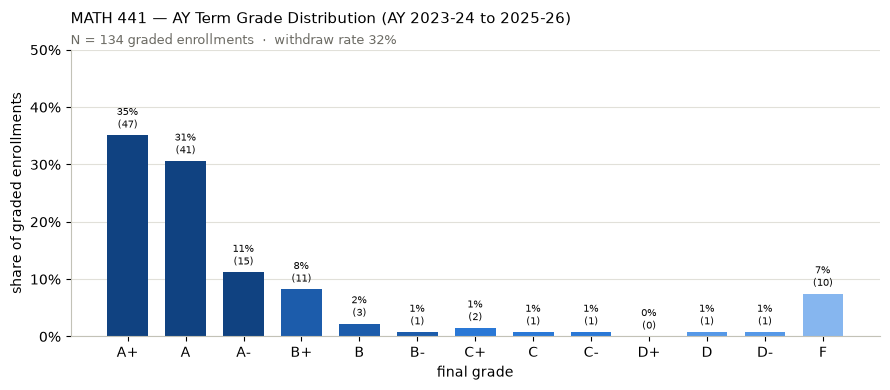

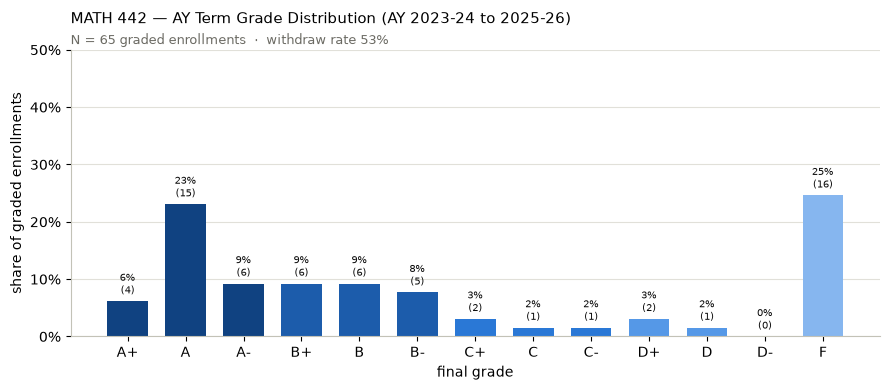

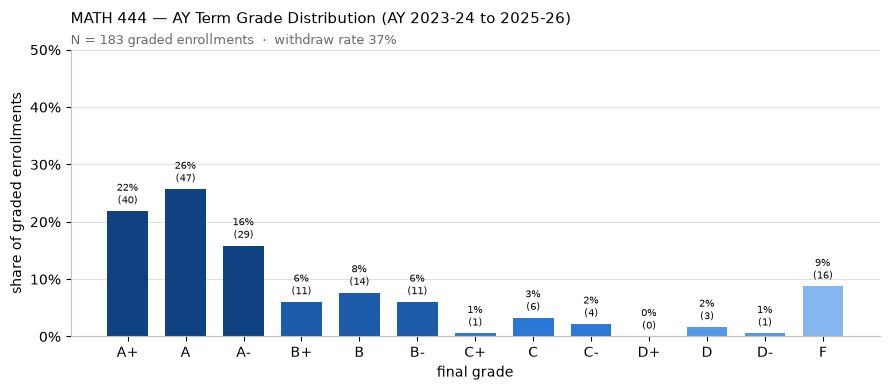

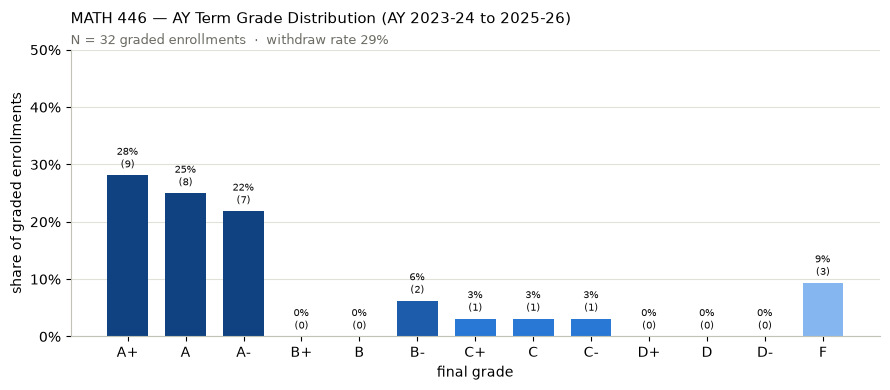

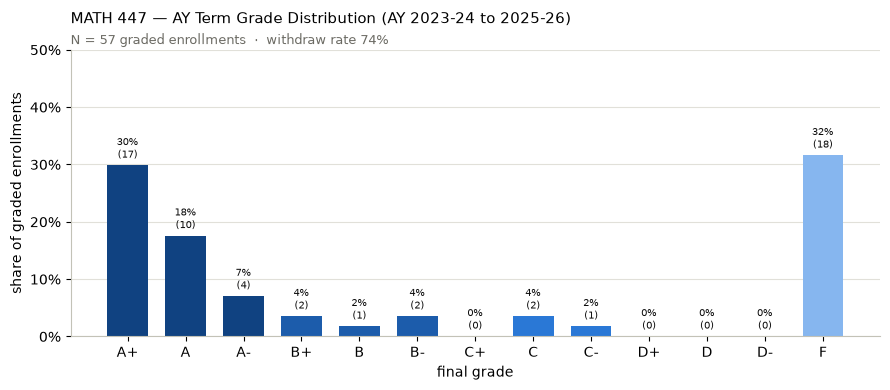

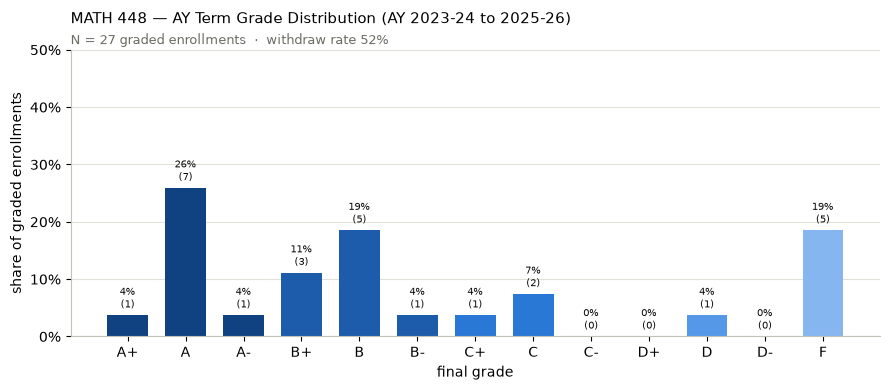

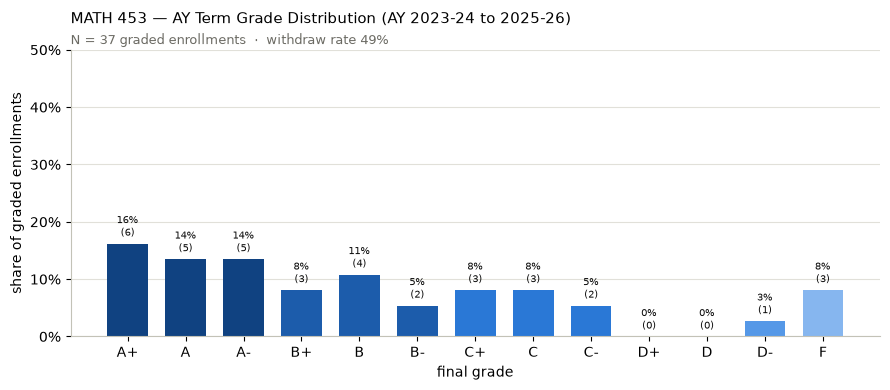

In [98]:
plt.style.use("default")
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"})
INK, MUTED, GRID, AXIS = "#0b0b0b", "#6b6a63", "#e1e0d9", "#c3c2b7"
LETTER_COLORS = {"A": "#104281", "B": "#1c5cab", "C": "#2a78d6", "D": "#5598e7", "F": "#86b6ef"}
BAR_COLORS = [LETTER_COLORS[g[0]] for g in GRADE_SCALE]

def style_axes(ax, grid_axis="y"):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(AXIS)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

AY_CHART_COURSES = ay_grade_counts.index[ay_grade_counts["N"] >= MIN_N]
print("courses with no graded enrollments (no chart):", [c for c in AY_COURSES if c not in ay_grade_counts.index])
print("small samples (own 0-100% y-axis):", ay_grade_counts.index[ay_grade_counts["N"] < MIN_N].tolist())
print("courses compared:", list(AY_CHART_COURSES))

AY_Y_MAX = (min(100, int(np.ceil((ay_grade_pct.loc[AY_CHART_COURSES].max().max() + 8) / 10) * 10))
            if len(AY_CHART_COURSES) else 100)

def plot_ay_course(course):
    y_max = AY_Y_MAX if course in AY_CHART_COURSES else 100
    pct, counts = ay_grade_pct.loc[course, GRADE_SCALE], ay_grade_counts.loc[course, GRADE_SCALE]
    n, wd = ay_grade_counts.loc[course, "N"], ay_summary.loc[course, "withdraw_rate"]

    fig, ax = plt.subplots(figsize=(9, 4))
    x = np.arange(len(GRADE_SCALE))
    ax.bar(x, pct, width=0.7, color=BAR_COLORS)
    for xi, p, c in zip(x, pct, counts):
        ax.text(xi, p + y_max * 0.015, f"{p:.0f}%\n({c})", ha="center", va="bottom", fontsize=7.5, color=INK)
    ax.set_xticks(x, GRADE_SCALE)
    ax.set_ylim(0, y_max)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
    ax.set_xlabel("final grade")
    ax.set_ylabel("share of graded enrollments")
    style_axes(ax)

    subtitle = f"N = {n} graded enrollments  ·  withdraw rate {wd:.0f}%"
    if n < MIN_N:
        subtitle += f"  ·  small sample (< {MIN_N}), y-axis 0–100%"
    ax.set_title(f"MATH {course} — AY Term Grade Distribution ({AY_LABEL})\n", fontsize=11, loc="left")
    ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9, color=MUTED)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / f"MATH {course} AY grade distribution.png", dpi=150)
    plt.show()

print(f"shared y-axis: 0–{AY_Y_MAX}%")
for course in ay_grade_counts.index:
    plot_ay_course(course)

### 3.0 All courses on one scale
One line per course (courses with at least `MIN_N` graded enrollments), legend sorted by A-range rate. Exact numbers: `ay_grade_pct` in §2.

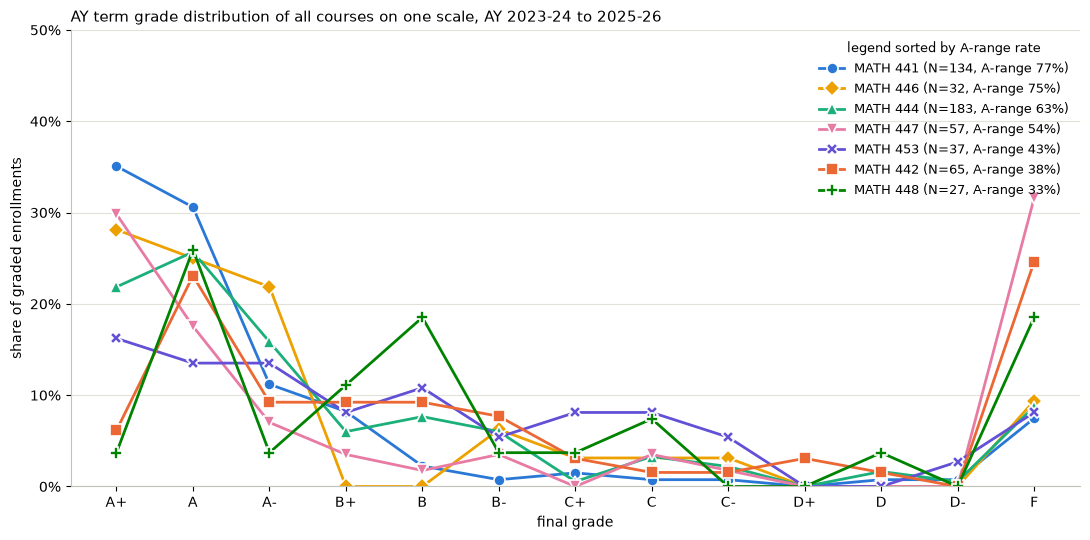

In [99]:
COURSE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
COURSE_MARKERS = ["o", "s", "^", "D", "v", "P", "X"]
ay_course_style = {c: (COURSE_COLORS[k], COURSE_MARKERS[k]) for k, c in enumerate(AY_COURSES)}  # fixed per course

x = np.arange(len(GRADE_SCALE))
fig, ax = plt.subplots(figsize=(11, 5.5))
for course in ay_summary.loc[AY_CHART_COURSES].sort_values("A_range_rate", ascending=False).index:
    color, marker = ay_course_style[course]
    ax.plot(x, ay_grade_pct.loc[course, GRADE_SCALE], color=color, linewidth=2, marker=marker, markersize=8,
            markeredgecolor="white", markeredgewidth=1.2,
            label=f"MATH {course} (N={ay_grade_counts.loc[course, 'N']}, A-range {ay_summary.loc[course, 'A_range_rate']:.0f}%)")
ax.set_xticks(x, GRADE_SCALE)
ax.set_ylim(0, AY_Y_MAX)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_xlabel("final grade")
ax.set_ylabel("share of graded enrollments")
style_axes(ax)
ax.legend(frameon=False, loc="upper right", fontsize=9, title="legend sorted by A-range rate", title_fontsize=9)
ax.set_title(f"AY term grade distribution of all courses on one scale, {AY_LABEL}", fontsize=11, loc="left")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "AY All courses grade distribution.png", dpi=150)
plt.show()

### 3.2 A-range rate vs D/F rate

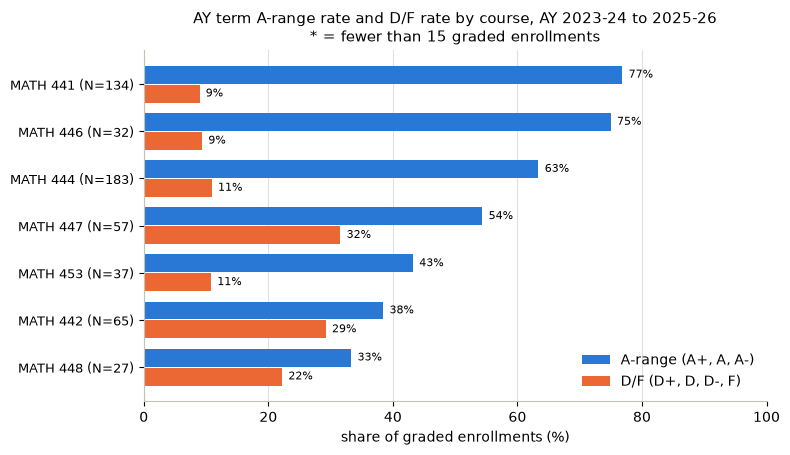

In [101]:
s = ay_summary[ay_summary["N_graded"] > 0].sort_values("A_range_rate")
y = np.arange(len(s))
fig, ax = plt.subplots(figsize=(8, 0.45 * len(s) + 1.5))
ax.barh(y + 0.2, s["A_range_rate"], height=0.38, color="#2a78d6", label="A-range (A+, A, A-)")
ax.barh(y - 0.2, s["DF_rate"], height=0.38, color="#eb6834", label="D/F (D+, D, D-, F)")
for yi, a, df_ in zip(y, s["A_range_rate"], s["DF_rate"]):
    ax.text(a + 1, yi + 0.2, f"{a:.0f}%", va="center", fontsize=8)
    ax.text(df_ + 1, yi - 0.2, f"{df_:.0f}%", va="center", fontsize=8)
ax.set_yticks(y, [f"MATH {c} (N={n})" + (" *" if n < MIN_N else "") for c, n in zip(s.index, s["N_graded"])], fontsize=9)
for label, n in zip(ax.get_yticklabels(), s["N_graded"]):
    if n < MIN_N:
        label.set_color(MUTED)
ax.set_xlim(0, 100)
ax.set_xlabel("share of graded enrollments (%)")
style_axes(ax, grid_axis="x")
ax.legend(frameon=False, loc="lower right")
ax.set_title(f"AY term A-range rate and D/F rate by course, {AY_LABEL}\n* = fewer than {MIN_N} graded enrollments", fontsize=11)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "AY A-range rate vs DF rate.png", dpi=150)
plt.show()